<font size = 7>DELE CA2 Part B: Reinforcement Learning </font>
<hr>
<font size = 4>

</font>

# Importing Required Modules

In [23]:
import gym
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import Model
from tensorflow.keras.optimizers import Adam
import numpy as np
import random
from collections import deque
import os
import matplotlib.pyplot as plt
from gym.wrappers import Monitor
import time
import seaborn as sns

In [2]:
# Fix random seed for reproducibility
seed = 1
np.random.seed(seed)
tf.random.set_seed(seed)
tf.keras.utils.set_random_seed(0)  

In [3]:
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

# Reinforcement Learning (RL)

**Reinforcement Learning (RL)** is a machine learning approach where an agent learns to make decisions by interacting with an environment. The goal is to train the agent to achieve a goal by taking actions that maximize cumulative reward.

**Components:**
- **Agent**: The learner or decision maker.
- **Environment**: The system the agent interacts with.
- **Actions**: Choices the agent can make.
- **State**: The current context or situation.
- **Reward**: Feedback from the environment, which can be positive or negative.

**Learning Process:**
- **Exploration**: Trying new actions to discover their effects.
- **Exploitation**: Using known actions that yield high rewards.

The agent learns through trial and error to develop a strategy (policy) that maximizes cumulative reward, also known as the return.

**Techniques**: Includes algorithms like Q-learning, Deep Q-Networks (DQN), and various policy gradient methods.


# Background Research on OpenAI Gym's Pendulum-v0

<img src='https://www.gymlibrary.dev/_images/pendulum.gif' width=300 height=300> 

**Pendulum-v0** is a classic continuous control problem provided by OpenAI Gym, designed to challenge reinforcement learning algorithms. It simulates an inverted pendulum, where the goal is to balance the pendulum upright.

#### **Environment Description**

- **State Space:**
  - **Angle (θ)**: The angle of the pendulum from the vertical, measured in radians. It ranges from -π to π.
  - **Angular Velocity (θ̇)**: The rate of change of the angle, also measured in radians/second, ranging from -8 to 8.

- **Action Space:**
  - The action is a continuous value representing the torque applied to the pendulum. It ranges from -2.0 to 2.0.

- **Reward Function:**
  - The reward is given at each time step and is computed based on the cosine of the angle and the angular velocity. Specifically, the reward is:
    \[
    \text{reward} = -(\text{angle}^2 + 0.1 \times \text{angular_velocity}^2 + 0.001 \times \text{torque}^2)
    \]
  - The goal is to maximize this reward, which corresponds to keeping the pendulum upright with minimal control effort.

- **Dynamics:**
  - The pendulum's dynamics are governed by a second-order differential equation. The equations of motion can be derived from the physics of a rigid pendulum and are used to update the state based on the current action.

#### **Challenges and Applications**

- **Challenges:**
  - **Continuous Control**: The continuous nature of both state and action spaces requires advanced RL algorithms capable of handling such environments.
  - **Stability**: Balancing the pendulum requires precise control and stability over time, making it a challenging control problem.

- **Applications:**
  - **Algorithm Development**: Pendulum-v0 is often used to test and develop reinforcement learning algorithms, especially those designed for continuous control problems.
  - **Benchmarking**: It serves as a benchmark problem for comparing the performance of different RL methods, including policy gradient methods, Q-learning variants, and actor-critic approaches.

# Initialise Gym Pendulum Environment

In [31]:
# Define the environment name for the OpenAI Gym
EnvName = 'Pendulum-v0'

# Create the environment using the specified name
env = gym.make(EnvName)

# Initialize a list to store rewards from the environment
rewards = []

# Specify how often to display the progress or results
ShowEvery = 10

# Define the shape of the input for the environment
InputShape = 3

# Deep Q-Network Agent (DQN)

## Introduction to DQN

Deep Q-Network (DQN) is a reinforcement learning algorithm introduced by DeepMind in 2013. It combines Q-learning with deep neural networks to handle high-dimensional state spaces. DQN uses a neural network to approximate the Q-function, which represents the expected future rewards for taking a given action in a particular state. This approach helps address the challenge of scaling Q-learning to environments with large or continuous state spaces.

## DQN Architecture and Learning

- **Q-Learning Basics**: Q-learning is a model-free reinforcement learning algorithm aimed at learning the optimal action-value function, \(Q^*(s, a)\). This function provides the expected cumulative reward for taking action \(a\) in state \(s\) and following the optimal policy thereafter.

- **Deep Q-Network**: DQN approximates the Q-function using a deep neural network. The network takes the state as input and outputs Q-values for all possible actions. Training involves updating the network parameters to minimize the difference between the predicted Q-values and the target Q-values, computed using the Bellman equation:
  \[
  y = r + \gamma \max_{a'} Q(s', a'; \theta^-)
  \]
  where \( \theta^- \) represents the parameters of the target network, and \(y\) is the target value for the current state-action pair.

- **Experience Replay**: To stabilize training, DQN uses a replay buffer to store past experiences. During training, mini-batches of experiences are sampled from this buffer to update the Q-network, helping break the correlation between consecutive updates and improving learning efficiency.

- **Target Network**: DQN employs a separate target network to compute the target Q-values. The target network's parameters are periodically updated with the Q-network’s parameters, which helps to stabilize training by preventing rapid changes in the targets.

## Challenges with DQN on Pendulum-v0

- **State Space Discretization**: DQN is designed for discrete action spaces, and Pendulum-v0 features a continuous action space. Discretizing the action space can lead to inefficiencies and suboptimal performance, as it may not capture the nuances of the continuous control problem.

- **Continuous Action Space**: In Pendulum-v0, the action space is continuous (torque values range from -2.0 to 2.0). Adapting DQN to handle continuous action spaces typically involves discretization, which may reduce control accuracy and performance.

- **Reward Signal**: The reward function in Pendulum-v0 includes a term for control effort, which introduces challenges in balancing between keeping the pendulum upright and minimizing control effort. This reward structure requires careful tuning and can impact the stability and efficiency of DQN.

## Alternatives and Extensions

- **Deep Deterministic Policy Gradient (DDPG)**: For continuous action spaces, algorithms like DDPG are more suitable than DQN. DDPG combines policy gradient methods with Q-learning and optimizes the policy directly in the continuous action space, avoiding the discretization issue.

- **Twin Delayed Deep Deterministic Policy Gradient (TD3)**: TD3 extends DDPG by incorporating techniques such as target policy smoothing, twin Q-networks, and delayed policy updates to improve stability and performance.

- **Soft Actor-Critic (SAC)**: SAC uses a probabilistic policy and maximizes a trade-off between reward and entropy. This approach offers improved performance and robustness for continuous control environments.


### Intialise Model

In [38]:
class DQN:
    def __init__(self,
                 InputShape=4,
                 NActions=2,
                 ReplayMemorySize=10000,
                 MinReplayMemory=1000,
                 UpdateTargetEveryThisEpisodes=1,
                 IntermediateSize=64,
                 LearningRate=0.001,
                 Gamma=0.95,  # Discount factor for future rewards
                 epsilon=1.0,  # Exploration rate
                 epsilon_min=0.02,  # Minimum value for exploration rate
                 epsilon_decay=0.995,  # Decay rate for exploration rate
                 BatchSize=32):
        
        # Hyperparameters initialization
        self.InputShape = InputShape
        self.NActions = NActions
        self.ReplayMemorySize = ReplayMemorySize
        self.MinReplayMemory = MinReplayMemory
        self.UpdateTargetEveryThisEpisodes = UpdateTargetEveryThisEpisodes
        self.IntermediateSize = IntermediateSize
        self.LearningRate = LearningRate
        self.Gamma = Gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.BatchSize = BatchSize
        
        # Create the main model (Q-function approximator)
        self.Main = self.CreateModel('Main')
        self.Optimiser = Adam(learning_rate=self.LearningRate)
        
        # Create the target model (used to stabilize training)
        self.Target = self.CreateModel('Target')
        # Initialize target model weights with main model weights
        self.Target.set_weights(self.Main.get_weights())
        
        # Replay memory to store experiences for training
        self.ReplayMemory = deque(maxlen=ReplayMemorySize)
        
        # Counter for tracking target network updates
        self.TargetUpdateCounter = 0
    
    def CreateModel(self, Type):
        """
        Creates a neural network model for Q-function approximation.

        Parameters:
        - Type: Indicates whether the model is 'Main' or 'Target'.

        Returns:
        - NN: The created Keras model.
        """
        # Define the input layer
        inputs = Input(shape=(self.InputShape,), name='Input')
        
        # Add hidden layers with ReLU activation
        x = Dense(self.IntermediateSize, activation='relu', name='1stHiddenLayer')(inputs)
        x = Dense(self.IntermediateSize, activation='relu', name='2ndHiddenLayer')(x)
        
        # Output layer with linear activation (Q-values for each action)
        outputs = Dense(self.NActions, activation='linear', name='Output')(x)
        
        # Create the model
        NN = Model(inputs, outputs, name=f'{Type}')
        NN.summary()  # Print model summary to check architecture
        
        return NN
    
    def UpdateReplayMemory(self, Information):
        """
        Adds a new experience to the replay memory.

        Parameters:
        - Information: A tuple (S, A, R, SNext, Done) representing state, action, reward, next state, and done flag.
        """
        self.ReplayMemory.append(Information)

    def Train(self, EndOfEpisode):
        """
        Trains the DQN model using a batch of experiences from replay memory.

        Parameters:
        - EndOfEpisode: Boolean flag indicating if the episode has ended (used to update target network).
        """
        # Only train if replay memory has enough data
        if len(self.ReplayMemory) < self.MinReplayMemory:
            print(f'DID NOT TRAIN..., replay memory = {len(self.ReplayMemory)}')
            return
        
        # Sample a batch of experiences from replay memory
        TrainingData = random.sample(self.ReplayMemory, self.BatchSize)
        
        # Extract states and Q-values from the batch
        ListOfS = np.array([element[0] for element in TrainingData])
        ListOfQ = np.array(self.Main(ListOfS))
        
        # Extract next states and corresponding Q-values
        ListOfSNext = np.array([element[3] for element in TrainingData])
        ListOfQNext = self.Target(ListOfSNext)
        
        # Prepare training data for the neural network
        X = []
        Y = []
        for index, (S, A, R, SNext, Done) in enumerate(TrainingData):
            if not Done:
                # Compute the target Q-value for non-terminal states
                MaxQNext = np.max(ListOfQNext[index])
                QNext = R + self.Gamma * MaxQNext
            else:
                # For terminal states, the target Q-value is just the reward
                QNext = R
            Q = ListOfQ[index]
            Q[A] = QNext
        
            X.append(S)
            Y.append(Q)
        
        # Train the model with the prepared data
        self.GTfit(X, Y)
                
        # Update target network periodically
        if EndOfEpisode:
            self.TargetUpdateCounter += 1
        
        if self.TargetUpdateCounter >= self.UpdateTargetEveryThisEpisodes:
            # Copy weights from main model to target model
            self.Target.set_weights(self.Main.get_weights())
            self.TargetUpdateCounter = 0

    @tf.function
    def GTfit(self, X, Y):
        """
        Performs a training step using TensorFlow's GradientTape for efficient training.

        Parameters:
        - X: Input states for training.
        - Y: Target Q-values for training.
        """
        with tf.GradientTape() as tape:
            # Predict Q-values for the current batch of states
            Predictions = self.Main(tf.convert_to_tensor(X), training=True)
            # Compute the loss between predicted Q-values and target Q-values
            Loss = tf.math.reduce_mean(tf.math.square(tf.convert_to_tensor(Y) - Predictions))
        
        # Compute gradients of the loss with respect to model weights
        Grad = tape.gradient(Loss, self.Main.trainable_variables)
        # Apply gradients to update model weights
        self.Optimiser.apply_gradients(zip(Grad, self.Main.trainable_variables))

## Define Hyperparameters

In [6]:
# Hyperparameters
NActions = 40
IntermediateSize = 64
LearningRate = 0.001
Gamma = 0.95
epsilon = 0.10
epsilon_min = 0.02
epsilon_decay = 0.995
BatchSize = 32

In [37]:
def PendulumActionConverter(A, NActions=NActions):
    """
    Converts an action index to an actual torque value for the Pendulum environment.
    
    Parameters:
    - A: Action index (integer) to be converted.
    - NActions: Total number of possible actions (default is set by the global NActions).
    
    Returns:
    - ActualTorque: Torque value corresponding to the action index.
    """
    # Convert action index to a torque value
    # Normalize the action index (A) to the range [-0.5, 0.5], then scale to [-4, 4]
    ActualTorque = (A / NActions - 0.5) * 4
    return ActualTorque

def PendulumInverseActionConverter(A, NActions=NActions):
    """
    Converts an actual torque value to an action index for the Pendulum environment.
    
    Parameters:
    - A: Torque value to be converted back to an action index.
    - NActions: Total number of possible actions (default is set by the global NActions).
    
    Returns:
    - ActualA: Action index corresponding to the given torque value.
    """
    # Convert torque value back to an action index
    # Scale torque value from [-4, 4] to [0, NActions-1], and round to the nearest integer
    ActualA = round((A + 2) * (NActions - 1) / 4)
    return ActualA


In [36]:
def Base_OneEpisode():
    """
    Runs a single episode using the DQN agent and updates the replay memory.
    """
    # Create a new environment instance
    env = gym.make(EnvName)
    
    # Reset the environment to get the initial state
    S = env.reset()
    
    # Initialize list to store rewards for this episode
    ListOfRewards = []
    
    # Flag to indicate if the episode has finished
    Done = False
    
    # Loop until the episode is finished
    while not Done:
        # Get Q-values from the DQN model for the current state
        Q = DQN.Main(S.reshape(-1, S.shape[0]))
        
        # Choose an action based on epsilon-greedy policy
        if np.random.rand() < epsilon:
            # Random action (exploration)
            AStep = env.action_space.sample()
            A = PendulumInverseActionConverter(AStep[0])
        else:
            # Best action based on Q-values (exploitation)
            A = np.argmax(Q)
            A = PendulumActionConverter(A)
            AStep = np.array([A])
            A = PendulumInverseActionConverter(A)
        
        # Render the environment periodically for visualization
        if not _ % ShowEvery and len(DQN.ReplayMemory) >= DQN.MinReplayMemory:
            env.render()
        
        # Take the selected action and observe the result
        SNext, R, Done, Info = env.step(AStep)
        
        # Update the replay memory with the new experience
        DQN.UpdateReplayMemory((S, A, R, SNext, Done))
        
        # Train the DQN model with the new experience
        DQN.Train(Done)
        
        # Append the reward received to the list for this episode
        ListOfRewards.append(R)
        
        # Check if the episode is finished
        if Done:
            # Print the total return (sum of rewards) for this episode
            print(f'Finished! Return: {np.sum(ListOfRewards)}')
            
            # Append the total return to the rewards list
            rewards.append(np.sum(ListOfRewards))
            
            # Close the environment to free resources
            env.close()
            
            return
        
        # Update the state to the next state
        S = SNext


## Plot function

In [9]:
def plot_rewards(rewards, window_size=10, title='Rewards over Episodes', xlabel='Episode', ylabel='Rewards', best_fit_line=True):

    # Ensure rewards is a numpy array
    rewards = np.array(rewards)
    
    if len(rewards) == 0:
        print("No rewards to plot.")
        return

    # Calculate and print the average reward
    average_reward = np.mean(rewards)
    print(f"Average Reward: {average_reward:.2f}")

    # Adjust the size of the figure
    plt.figure(figsize=(12, 6))

    # Plot raw rewards
    plt.plot(rewards, label='Rewards', alpha=0.5)

    # Calculate and plot a moving average to smooth the reward data
    if window_size > 1:
        smoothed_rewards = np.convolve(rewards, np.ones(window_size)/window_size, mode='valid')
        plt.plot(np.arange(window_size-1, len(rewards)), smoothed_rewards, color='green', label=f'{window_size}-Episode Moving Average')

    # Add a best-fit line if needed
    if best_fit_line:
        x = np.arange(len(rewards))  # Create an array of indices
        coefficients = np.polyfit(x, rewards, 1)  # Fit a 1st degree polynomial (linear)
        best_fit_line = np.poly1d(coefficients)  # Create a polynomial function
        plt.plot(x, best_fit_line(x), color='red', linestyle='--', label='Best Fit Line')

    # Add labels and title
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend()  # Show legend

    # Show the plot
    plt.show()

## Running Base Model

In [10]:
STARTTIME = time.time()

rewards.clear()
DQN = DQN(InputShape=InputShape, 
          NActions=NActions, 
          IntermediateSize=IntermediateSize,
          LearningRate=LearningRate,
          Gamma=Gamma,
          epsilon=epsilon,
          epsilon_decay=epsilon_decay,
          epsilon_min=epsilon_min,
          BatchSize=BatchSize)

for _ in range(150):
    print(f'Episode {_}')
    Base_OneEpisode()

print(f'Total time taken: {time.time() - STARTTIME} seconds ...')

Model: "Main"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Input (InputLayer)                   │ (None, 3)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 1stHiddenLayer (Dense)               │ (None, 64)                  │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 2ndHiddenLayer (Dense)               │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output (Dense)                       │ (None, 40)                  │           2,600 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,016 (27.41 KB)

 Trainable params: 7,016 (27.41 KB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Input (InputLayer)                   │ (None, 3)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 1stHiddenLayer (Dense)               │ (None, 64)                  │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 2ndHiddenLayer (Dense)               │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output (Dense)                       │ (None, 40)                  │           2,600 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,016 (27.41 KB)

 Trainable params: 7,016 (27.41 KB)

 Non-trainable params: 0 (0.00 B)

Episode 0
DID NOT TRAIN..., replay memory = 1
DID NOT TRAIN..., replay memory = 2
DID NOT TRAIN..., replay memory = 3
DID NOT TRAIN..., replay memory = 4
DID NOT TRAIN..., replay memory = 5
DID NOT TRAIN..., replay memory = 6
DID NOT TRAIN..., replay memory = 7
DID NOT TRAIN..., replay memory = 8
DID NOT TRAIN..., replay memory = 9
DID NOT TRAIN..., replay memory = 10
DID NOT TRAIN..., replay memory = 11
DID NOT TRAIN..., replay memory = 12
DID NOT TRAIN..., replay memory = 13
DID NOT TRAIN..., replay memory = 14
DID NOT TRAIN..., replay memory = 15
DID NOT TRAIN..., replay memory = 16
DID NOT TRAIN..., replay memory = 17
DID NOT TRAIN..., replay memory = 18
DID NOT TRAIN..., replay memory = 19
DID NOT TRAIN..., replay memory = 20
DID NOT TRAIN..., replay memory = 21
DID NOT TRAIN..., replay memory = 22
DID NOT TRAIN..., replay memory = 23
DID NOT TRAIN..., replay memory = 24
DID NOT TRAIN..., replay memory = 25
DID NOT TRAIN..., replay memory = 26
DID NOT TRAIN..., replay memory = 27


Average Reward: -839.20


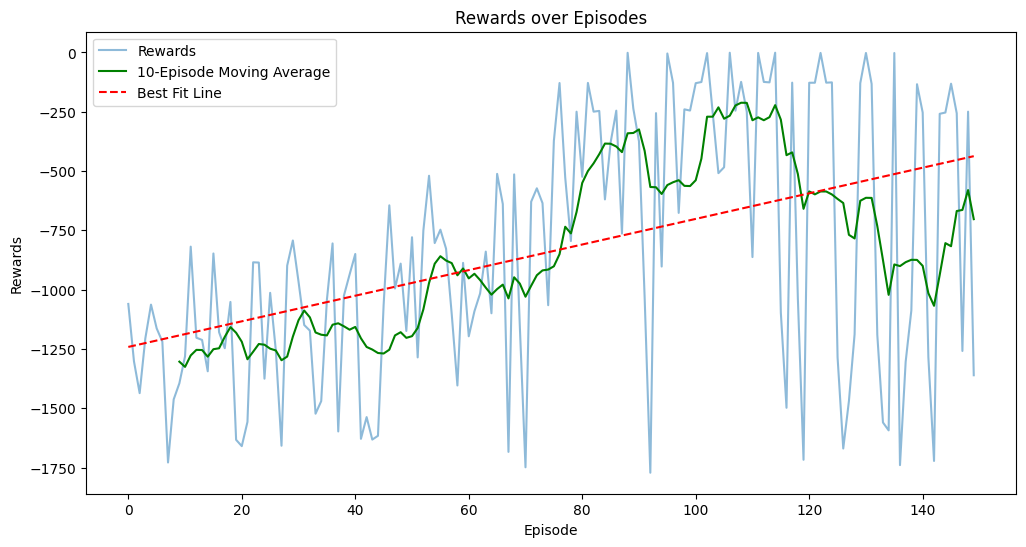

In [11]:
plot_rewards(rewards)

## Epsilon Decay

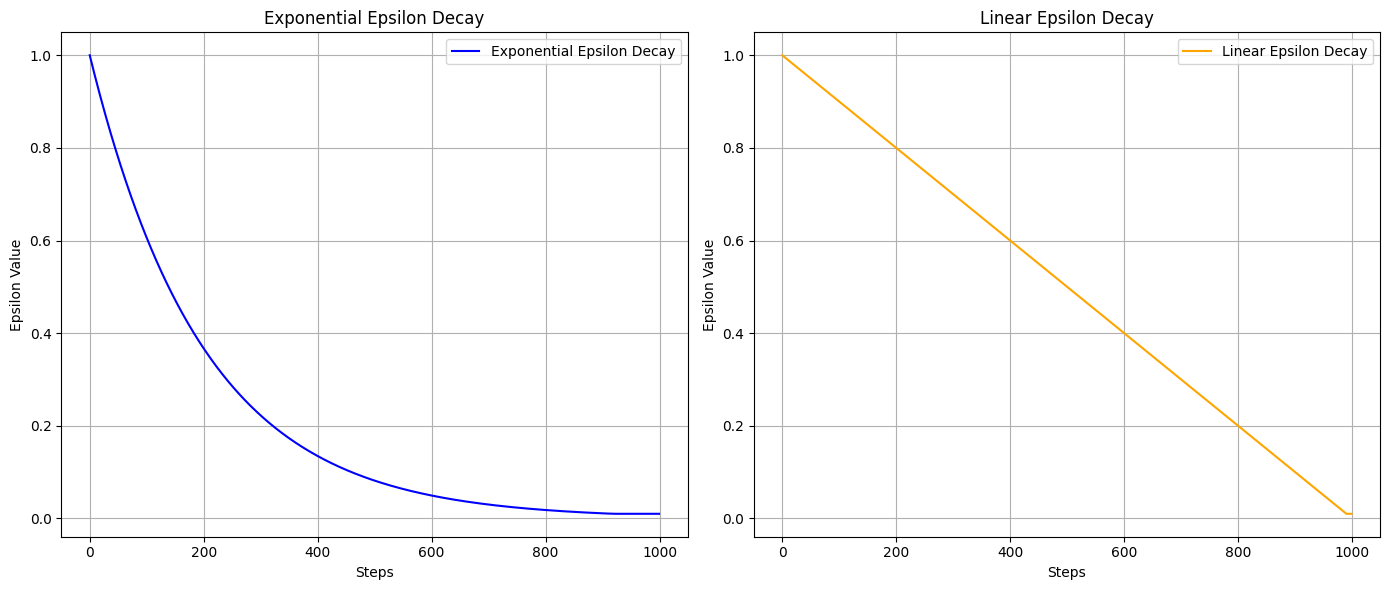

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters for exponential decay
initial_epsilon = 1.0        
epsilon_decay = 0.995        
min_epsilon = 0.01          
num_steps = 1000            

# Compute exponential epsilon values
epsilons_exp = []
epsilon = initial_epsilon
for step in range(num_steps):
    epsilons_exp.append(epsilon)
    epsilon = max(min_epsilon, epsilon * epsilon_decay)

# Parameters for linear decay
epsilon_decay_rate = 0.001   # Decay amount per step (linear)

# Compute linear epsilon values
epsilons_linear = []
epsilon = initial_epsilon
for step in range(num_steps):
    epsilons_linear.append(epsilon)
    epsilon -= epsilon_decay_rate
    epsilon = max(min_epsilon, epsilon)  # Ensure epsilon doesn't go below min_epsilon

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Exponential Decay Plot
ax1.plot(epsilons_exp, label='Exponential Epsilon Decay', color='blue')
ax1.set_xlabel('Steps')
ax1.set_ylabel('Epsilon Value')
ax1.set_title('Exponential Epsilon Decay')
ax1.legend()
ax1.grid(True)

# Linear Decay Plot
ax2.plot(epsilons_linear, label='Linear Epsilon Decay', color='orange')
ax2.set_xlabel('Steps')
ax2.set_ylabel('Epsilon Value')
ax2.set_title('Linear Epsilon Decay')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

## Tuned Exponential Epsilon Decay

In [35]:
class Tuned_DQN:
    def __init__(self,
                 InputShape = 4,
                 NActions = 2,
                 ReplayMemorySize = 10000,
                 MinReplayMemory = 1000,
                 UpdateTargetEveryThisEpisodes = 1,
                 IntermediateSize = 64,   
                 LearningRate = 0.001,
                 Gamma = 0.95,  # Rate of Discount
                 epsilon = 1.0,  # Rate of Exploration
                 epsilon_min = 0.02,
                 epsilon_decay = 0.995,
                 BatchSize = 32):
        """
        Initialize the Tuned_DQN class with hyperparameters and model setup.
        """
        # Hyperparameters
        self.InputShape = InputShape
        self.NActions = NActions
        self.ReplayMemorySize = ReplayMemorySize
        self.MinReplayMemory = MinReplayMemory
        self.UpdateTargetEveryThisEpisodes = UpdateTargetEveryThisEpisodes
        self.IntermediateSize = IntermediateSize
        self.LearningRate = LearningRate
        self.Gamma = Gamma
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.BatchSize = BatchSize
        
        # Main Q-network model
        self.Main = self.CreateModel('Main')
        self.Optimiser = Adam(learning_rate=self.LearningRate)
        
        # Target Q-network model (used for calculating target Q-values)
        self.Target = self.CreateModel('Target')
        self.Target.set_weights(self.Main.get_weights())
        
        # Replay memory to store past experiences
        self.ReplayMemory = deque(maxlen=self.ReplayMemorySize)
        
        # Counter to track the number of episodes before updating the target network
        self.TargetUpdateCounter = 0
    
    def CreateModel(self, Type):
        """
        Create a Q-network model with specified architecture.
        
        Parameters:
        - Type: Specifies whether the model is 'Main' or 'Target'.
        
        Returns:
        - NN: A compiled Neural Network model.
        """
        inputs = Input(shape=(self.InputShape,), name='Input')
        x = Dense(self.IntermediateSize, activation='relu', name='1stHiddenLayer')(inputs)
        x = Dense(self.IntermediateSize, activation='relu', name='2ndHiddenLayer')(x)
        outputs = Dense(self.NActions, activation='linear', name='Output')(x)
        
        NN = Model(inputs, outputs, name=f'{Type}')
        NN.summary()
        
        return NN
    
    def UpdateReplayMemory(self, Information):
        """
        Add a new experience tuple to the replay memory.
        
        Parameters:
        - Information: A tuple (S, A, R, SNext, Done) representing the experience.
        """
        self.ReplayMemory.append(Information)

    def Train(self, EndOfEpisode):
        """
        Train the Q-network using a batch of experiences from replay memory.
        
        Parameters:
        - EndOfEpisode: Boolean flag indicating if the current episode has ended (for target network update).
        """
        # Check if replay memory has enough data to train
        if len(self.ReplayMemory) < self.MinReplayMemory:
            print(f'DID NOT TRAIN..., replay memory = {len(self.ReplayMemory)}')
            return
        
        # Sample a batch of experiences from replay memory
        TrainingData = random.sample(self.ReplayMemory, self.BatchSize)
        
        # Extract states and Q-values for training
        ListOfS = np.array([element[0] for element in TrainingData])
        ListOfQ = np.array(self.Main(ListOfS))
        
        # Extract future states and Q-values from target network
        ListOfSNext = np.array([element[3] for element in TrainingData])
        ListOfQNext = self.Target(ListOfSNext)
        
        # Prepare data for training the model
        X = []
        Y = []
        for index, (S, A, R, SNext, Done) in enumerate(TrainingData):
            if not Done:
                MaxQNext = np.max(ListOfQNext[index])
                QNext = R + self.Gamma * MaxQNext
            else:
                QNext = R
            Q = ListOfQ[index]
            Q[A] = QNext
        
            X.append(S)
            Y.append(Q)
        
        # Train the model using gradient tape
        self.GTfit(X, Y)
                
        # Update target network every specified number of episodes
        if EndOfEpisode:
            self.TargetUpdateCounter += 1
        
        if self.TargetUpdateCounter >= self.UpdateTargetEveryThisEpisodes:
            self.Target.set_weights(self.Main.get_weights())
            self.TargetUpdateCounter = 0

    @tf.function
    def GTfit(self, X, Y):
        """
        Perform training using TensorFlow GradientTape for improved performance.
        
        Parameters:
        - X: Input states.
        - Y: Target Q-values.
        """
        with tf.GradientTape() as tape:
            Predictions = self.Main(tf.convert_to_tensor(X), training=True)
            Loss = tf.math.reduce_mean(tf.math.square(tf.convert_to_tensor(Y) - Predictions))
        Grad = tape.gradient(Loss, self.Main.trainable_variables)
        self.Optimiser.apply_gradients(zip(Grad, self.Main.trainable_variables))

In [14]:
# Hyperparameters
NActions = 23
IntermediateSize = 64
LearningRate = 0.0005
Gamma = 0.90
epsilon = 0.40
epsilon_min = 0.02
epsilon_decay = 0.995
BatchSize = 32

In [34]:
def PendulumActionConverter(A, NActions=NActions):
    """
    Convert the discrete action index to a continuous torque value for the Pendulum environment.
    
    Parameters:
    - A: Discrete action index.
    - NActions: Number of discrete actions (used to normalize the action).
    
    Returns:
    - ActualTorque: The corresponding continuous torque value.
    """
    ActualTorque = (A / NActions - 0.5) * 4
    return ActualTorque

def PendulumInverseActionConverter(A, NActions=NActions):
    """
    Convert a continuous torque value back to a discrete action index for the Pendulum environment.
    
    Parameters:
    - A: Continuous torque value.
    - NActions: Number of discrete actions (used to de-normalize the action).
    
    Returns:
    - ActualA: The corresponding discrete action index.
    """
    ActualA = round((A + 2) * (NActions - 1) / 4)
    return ActualA

def OneEpisode(episode):
    """
    Run one episode of the environment using the DQN agent.
    
    Parameters:
    - episode: The current episode number, used for saving weights and logging.
    """
    # Reset the environment for the new episode and initialize variables
    S = env.reset()
    ListOfRewards = []
    Done = False

    # Loop until the episode is done
    while not Done:
        # Get Q-values from the DQN model for the current state
        Q = Tuned_DQN.Main(S.reshape(-1, S.shape[0]))
        
        # Choose action based on epsilon-greedy strategy
        if np.random.rand() < epsilon:
            # Choose a random action (exploration)
            AStep = env.action_space.sample()
            A = PendulumInverseActionConverter(AStep[0])
        else:
            # Choose the best action based on Q-values (exploitation)
            A = np.argmax(Q)
            A = PendulumActionConverter(A)
            AStep = np.array([A])
            A = PendulumInverseActionConverter(A)
        
        # Render the environment periodically for visualization
        if not episode % ShowEvery and len(Tuned_DQN.ReplayMemory) >= Tuned_DQN.MinReplayMemory:
            env.render()
        
        # Take the selected action and observe the result
        SNext, R, Done, Info = env.step(AStep)
        
        # Update the replay memory with the new experience
        Tuned_DQN.UpdateReplayMemory((S, A, R, SNext, Done))
        
        # Train the DQN model with the new experience
        Tuned_DQN.Train(Done)
        
        # Append the reward received to the list for this episode
        ListOfRewards.append(R)
        
        # Check if the episode is finished
        if Done:
            # Print the total return (sum of rewards) for this episode
            print(f'Finished! Return: {np.sum(ListOfRewards)}')
            
            # Append the total return to the rewards list
            rewards.append(np.sum(ListOfRewards))
            
            # Save the weights of the DQN model after each episode
            Tuned_DQN.Main.save_weights(f'saved{episode}.weights.h5')
            
            # Close the environment to free resources
            env.close() 
            
            # Update epsilon to reduce exploration over time
            Tuned_DQN.epsilon = max(0.01, Tuned_DQN.epsilon * Tuned_DQN.epsilon_decay)
            
            return
        
        # Update the state to the next state
        S = SNext


In [16]:
STARTTIME = time.time()

os.chdir(r"C:\SP\Year 2 Sem 1\DEEP\CA2\PART B\saved.weights.h5")

rewards.clear()
print(NActions)
Tuned_DQN = Tuned_DQN(InputShape=InputShape, 
          NActions=NActions, 
          IntermediateSize=IntermediateSize,
          LearningRate=LearningRate,
          Gamma=Gamma,
          epsilon=epsilon,
          epsilon_decay=epsilon_decay,
          epsilon_min=epsilon_min,
          BatchSize=BatchSize)

for _ in range(150):
    print(f'Episode {_}')
    OneEpisode(_)

print(f'Total time taken: {time.time() - STARTTIME} seconds ...')

23


Model: "Main"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Input (InputLayer)                   │ (None, 3)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 1stHiddenLayer (Dense)               │ (None, 64)                  │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 2ndHiddenLayer (Dense)               │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output (Dense)                       │ (None, 23)                  │           1,495 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,911 (23.09 KB)

 Trainable params: 5,911 (23.09 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ Input (InputLayer)                   │ (None, 3)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 1stHiddenLayer (Dense)               │ (None, 64)                  │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ 2ndHiddenLayer (Dense)               │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ Output (Dense)                       │ (None, 23)                  │           1,495 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,911 (23.09 KB)

 Trainable params: 5,911 (23.09 KB)

 Non-trainable params: 0 (0.00 B)

Episode 0
DID NOT TRAIN..., replay memory = 1
DID NOT TRAIN..., replay memory = 2
DID NOT TRAIN..., replay memory = 3
DID NOT TRAIN..., replay memory = 4
DID NOT TRAIN..., replay memory = 5
DID NOT TRAIN..., replay memory = 6
DID NOT TRAIN..., replay memory = 7
DID NOT TRAIN..., replay memory = 8
DID NOT TRAIN..., replay memory = 9
DID NOT TRAIN..., replay memory = 10
DID NOT TRAIN..., replay memory = 11
DID NOT TRAIN..., replay memory = 12
DID NOT TRAIN..., replay memory = 13
DID NOT TRAIN..., replay memory = 14
DID NOT TRAIN..., replay memory = 15
DID NOT TRAIN..., replay memory = 16
DID NOT TRAIN..., replay memory = 17
DID NOT TRAIN..., replay memory = 18
DID NOT TRAIN..., replay memory = 19
DID NOT TRAIN..., replay memory = 20
DID NOT TRAIN..., replay memory = 21
DID NOT TRAIN..., replay memory = 22
DID NOT TRAIN..., replay memory = 23
DID NOT TRAIN..., replay memory = 24
DID NOT TRAIN..., replay memory = 25
DID NOT TRAIN..., replay memory = 26
DID NOT TRAIN..., replay memory = 27


Average Reward: -760.43


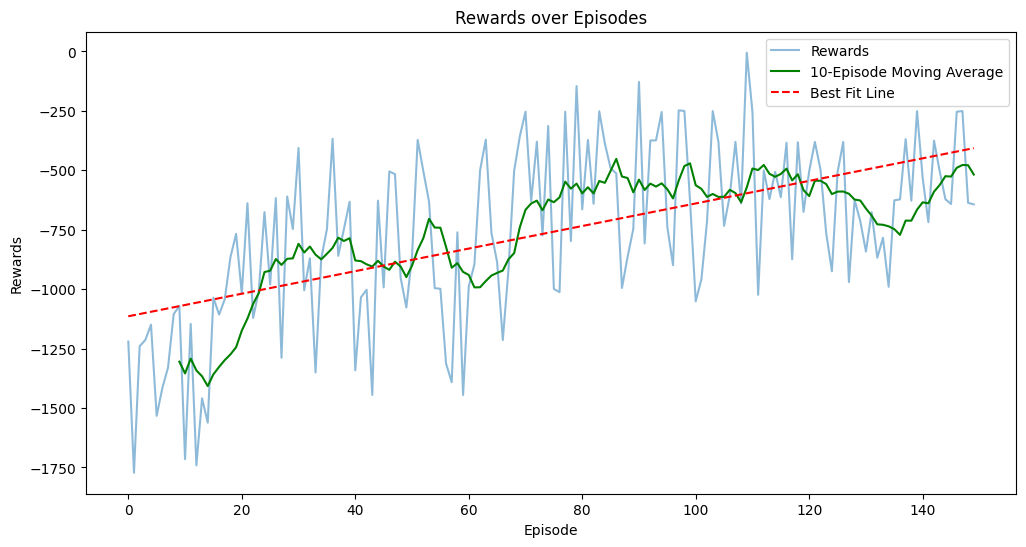

In [18]:
plot_rewards(rewards)

## Generate weights 10 times

Finished! Return: -3.2468276522477355
Finished! Return: -1322.2173287691467
Finished! Return: -125.71346620717861
Finished! Return: -2.491496484425367
Finished! Return: -865.6003793010675
Finished! Return: -382.18011209292996
Finished! Return: -1020.8775883002522
Finished! Return: -2.389860192036898
Finished! Return: -1065.3611022611765
Finished! Return: -256.1427107491224
Average reward over 10 episodes:  -504.6220872009584


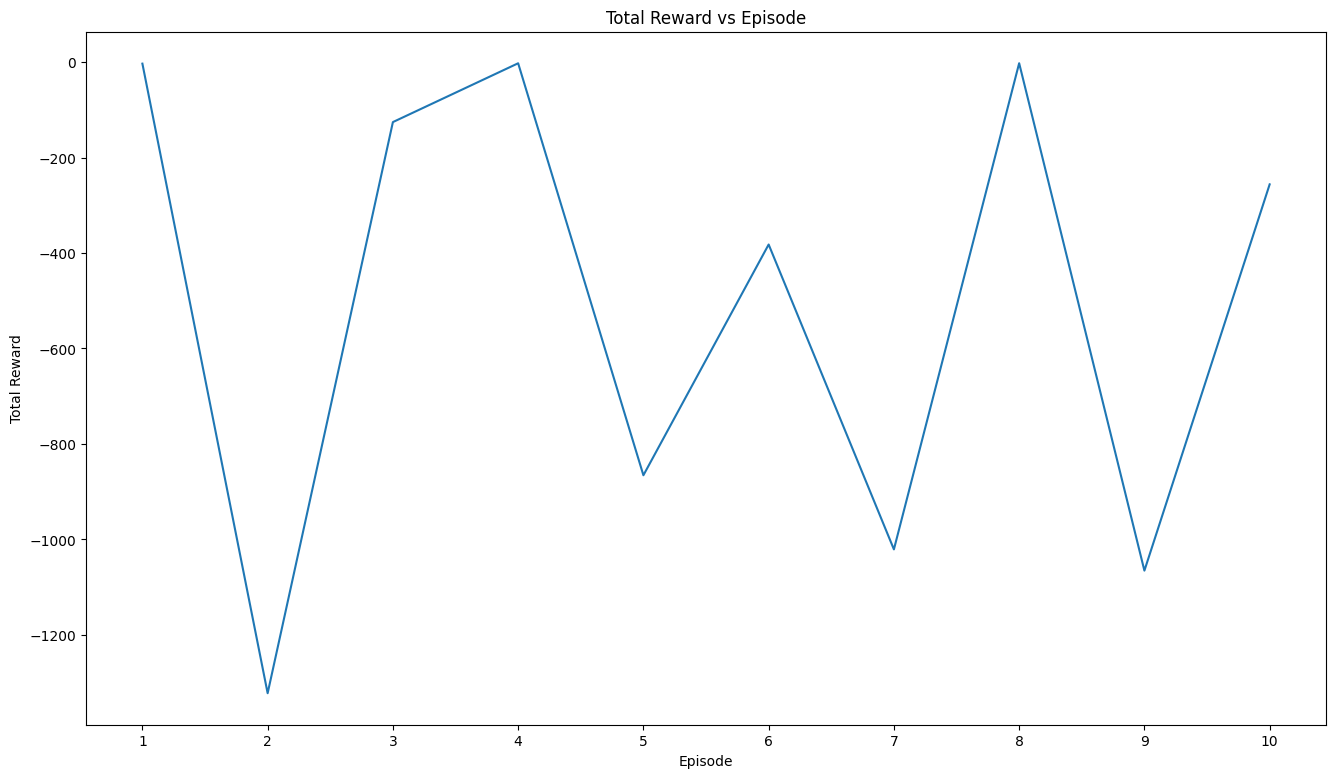

In [33]:
# Load the weights into the DQN model
Tuned_DQN.Main.load_weights("C:\\SP\\Year 2 Sem 1\\DEEP\\CA2\\PART B\\saved118.weights.h5")

# Save the weights to a new file (this is redundant if you don't plan to change weights)
Tuned_DQN.Main.save_weights("saved118.weights.h5")

# Define the number of test episodes
num_test_episodes = 10

# Initialize a list to store the total reward for each testing episode
testing_episode_reward = []

# Run the specified number of test episodes
for _ in range(num_test_episodes):
    # Create a new instance of the environment for each episode
    env = gym.make(f'{EnvName}')
    
    # Reset the environment to start a new episode
    S = env.reset()
    
    # Initialize the list to store rewards for the current episode
    ListOfRewards = []
    
    # Flag to indicate if the episode has finished
    Done = False

    # Loop until the episode is done
    while not Done:
        # Get Q-values from the DQN model for the current state
        Q = DQN.Main(S.reshape(-1, S.shape[0]))
        
        # Choose the action with the highest Q-value
        A = np.argmax(Q)
        
        # Convert the action to the appropriate format for the Pendulum environment
        A = PendulumActionConverter(A)
        
        # Create an array of the selected action
        AStep = np.array([A])
        
        # Perform the action in the environment
        SNext, R, Done, Info = env.step(AStep)
        
        # Render the environment to visualize the simulation
        env.render()
        
        # Append the reward received to the list of rewards for the current episode
        ListOfRewards.append(R)
        
        # Check if the episode has ended
        if Done:
            # Print the total return (sum of rewards) for the episode
            print(f'Finished! Return: {np.sum(ListOfRewards)}')
            
            # Append the total return to the list of testing episode rewards
            testing_episode_reward.append(np.sum(ListOfRewards))
            
            # Close the environment to free resources
            env.close()
            break
        
        # Update the current state to the next state
        S = SNext

# Print the average reward obtained over all test episodes
print(f"Average reward over {num_test_episodes} episodes: ", np.mean(testing_episode_reward))

# Plot the total reward for each episode
plt.figure(figsize=(16, 9))
sns.lineplot(x=range(len(testing_episode_reward)), y=testing_episode_reward)
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('Total Reward vs Episode')
plt.xticks(ticks=range(len(testing_episode_reward)), labels=range(1, len(testing_episode_reward) + 1))
plt.show()